Лабораторная работа № 3.СВЁРТОЧНЫЕ НЕЙРОННЫЕ СЕТИ И ПЕРЕНОС ОБУЧЕНИЯ ДЛЯ КЛАССИФИКАЦИИ ИЗОБРАЖЕНИЙ

Выполнили Лебёдкин Владислав, Травкова Ирина. Группа 932302

Вариант 4.

В данном файле реализованы задачи 1, 2, 7, 8, 9 для трёхклассовой классификации. Бинарная классификация реализована в блокноте ``сверточные_нейронные_сети.ipynb``

In [3]:
# Импорт библиотек
import os
import gc
import hashlib
import platform
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn

from PIL import Image
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")

# Фиксация seed для воспроизводимости
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Пути
DATA_DIR = Path(r"C:\Users\Ирина\Desktop\ml\Нейронные сети\лаб3\PlantVillage")
FIGURES_DIR = Path("figures")
RESULTS_DIR = Path("results")
MODELS_DIR = Path("models")
for d in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    d.mkdir(exist_ok=True)

# Параметры изображений
IMAGE_SIZE = 224
BATCH_SIZE = 32

# Вариант 4: три класса томата
CLASS_FOLDERS = [
    "Tomato__Tomato_YellowLeaf__Curl_Virus",  # класс 0
    "Tomato_healthy",                 # класс 1
    "Tomato_Septoria_leaf_spot",      # класс 2
]
CLASS_NAMES = ["Жёлтая курчавость (вирус)", "Здоровый", "Септориоз"]
CLASS_COLORS = ["#d62728", "#2ca02c", "#ff7f0e"]
TRAIN_COLOR, VAL_COLOR, TEST_COLOR = "#2a78d6", "#eb6834", "#52514e"
NUMBER_OF_CLASSES = len(CLASS_FOLDERS)
ALL_LABELS = list(range(NUMBER_OF_CLASSES))

# Настройки обучения
HEAD_LEARNING_RATE = 0.001  # режим A
MAX_EPOCHS_FROZEN = 40
UNFROZEN_LAYERS = 30  # режим B: размораживаем последние 30 слоёв
FINE_TUNE_LEARNING_RATES = [1e-5, 1e-4]
MAX_EPOCHS_FINE = 30
PATIENCE = 8
LOSS_TOLERANCE = 0.01

# Графики
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200,
    "font.size": 12, "axes.grid": True,
})

# Версии библиотек и оборудование
print(f"tensorflow: {tf.__version__}")
print(f"sklearn: {sklearn.__version__}")
print(f"numpy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"Python: {platform.python_version()}")
print(f"GPU: {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}")
print(f"Seed: {SEED}")

tensorflow: 2.21.0
sklearn: 1.7.2
numpy: 2.2.6
pandas: 2.3.0
Python: 3.10.5
GPU: CPU
Seed: 42


### 0. Описание набора данных

**Источник:** PlantVillage (Kaggle: https://www.kaggle.com/datasets/emmarex/plantdisease).

**Задача:** по фотографии листа томата предсказать его фитосанитарное состояние — один из трёх классов. Такая модель применяется для ранней диагностики заболеваний: фермер фотографирует лист смартфоном и получает прогноз до того, как болезнь распространится по полю.

**Вариант 4:** три класса томата:

| № | Папка | Болезнь | Признаки |
|---|-------|---------|----------|
| 0 | `Tomato___Yellow_Leaf_Curl_Virus` | Жёлтая курчавость (TYLCV) | скручивание листьев, хлороз, карликовость |
| 1 | `Tomato___healthy` | Здоровый лист | равномерно зелёный, без пятен |
| 2 | `Tomato___Septoria_leaf_spot` | Септориоз | мелкие бурые пятна с тёмной каймой и светлым центром |

**Структура записи:** каждая запись — это цветная фотография одного листа, снятая сверху на однородном фоне. Метка класса определяется папкой, в которой лежит файл. Имя файла служит уникальным идентификатором снимка.

**Размерность:** исходные изображения — RGB, 256×256 пикселей, 8 бит на канал. Для подачи в сеть они приводятся к 224×224×3 и нормализуются функцией mobilenet_v2.preprocess_input (диапазон значений [−1; 1]).

### 1. Таблица файлов набора данных и проверка корректности

Собираем таблицу всех изображений трёх классов варианта. Для каждого файла сохраняем относительный путь, название папки (класса) и числовую метку. Проверяем, что все три папки существуют, и фильтруем только файлы изображений (`.jpg`, `.jpeg`, `.png`). Выводим общее количество файлов, распределение расширений и случайную выборку для визуальной проверки.

In [4]:
# Собираем таблицу файлов трёх классов
file_records = []
for label, folder in enumerate(CLASS_FOLDERS):
    folder_path = DATA_DIR / folder
    if not folder_path.is_dir():
        raise FileNotFoundError(f"Не найдена папка: {folder_path}")
    for path in sorted(folder_path.iterdir()):
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            file_records.append({
                "file": f"{folder}/{path.name}",
                "folder": folder,
                "label": label,
            })

files = pd.DataFrame(file_records)
print(f"Всего файлов в трёх папках: {len(files)}")
print("Расширения файлов:", files["file"].str.rsplit(".", n=1).str[-1].value_counts().to_dict())
display(files.sample(8, random_state=SEED))

Всего файлов в трёх папках: 6570
Расширения файлов: {'JPG': 6569, 'jpg': 1}


,file,folder,label
5364,Tomato_Septoria_leaf_spot/573c904e-8ccd-4a27-9...,Tomato_Septoria_leaf_spot,2
5586,Tomato_Septoria_leaf_spot/7a21a34c-b9a4-4a3a-8...,Tomato_Septoria_leaf_spot,2
2623,Tomato__Tomato_YellowLeaf__Curl_Virus/7b49148d...,Tomato__Tomato_YellowLeaf__Curl_Virus,0
5939,Tomato_Septoria_leaf_spot/abb40b01-9ffd-4dd8-b...,Tomato_Septoria_leaf_spot,2
1360,Tomato__Tomato_YellowLeaf__Curl_Virus/40726129...,Tomato__Tomato_YellowLeaf__Curl_Virus,0
496,Tomato__Tomato_YellowLeaf__Curl_Virus/17e67b5d...,Tomato__Tomato_YellowLeaf__Curl_Virus,0
5409,Tomato_Septoria_leaf_spot/5e8d580c-23b6-44e4-b...,Tomato_Septoria_leaf_spot,2
2955,Tomato__Tomato_YellowLeaf__Curl_Virus/8a910cae...,Tomato__Tomato_YellowLeaf__Curl_Virus,0


### 2. Проверка повреждённых файлов, размеров и формата

Для каждого изображения в наборе данных выполняем базовые проверки качества:
1. **Целостность файла:** используем метод `img.verify()`, чтобы убедиться, что файл не повреждён и может быть корректно декодирован библиотекой PIL.
2. **Метаданные:** извлекаем физические размеры (ширина, высота) и цветовой режим (RGB, RGBA и т.д.).
3. **MD5-хэш:** вычисляем хэш содержимого файла. Это необходимо для последующего поиска и удаления точных дубликатов (копий файлов).

Результаты проверок объединяются с основной таблицей файлов. В конце выводим сводную статистику: количество повреждённых файлов, распределение размеров и цветовых режимов. Это позволяет убедиться, что все изображения имеют единый формат перед подачей в нейронную сеть.

In [5]:
def inspect_image(relative_path):
    content = (DATA_DIR / relative_path).read_bytes()
    try:
        with Image.open(DATA_DIR / relative_path) as img:
            img.verify()
        with Image.open(DATA_DIR / relative_path) as img:
            img = img.convert("RGB")
            return {
                "readable": True,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "md5": hashlib.md5(content).hexdigest(),
            }
    except Exception as error:
        print("Повреждённый файл:", relative_path, error)
        return {
            "readable": False,
            "width": 0, "height": 0, "mode": "",
            "md5": hashlib.md5(content).hexdigest(),
        }

inspection = pd.DataFrame([inspect_image(p) for p in files["file"]])
files = pd.concat([files, inspection], axis=1)

print("Повреждённых файлов:", int((~files["readable"]).sum()))
print("Размеры (ширина x высота):", files.groupby(["width", "height"]).size().to_dict())
print("Цветовые режимы:", files["mode"].value_counts().to_dict())

Повреждённых файлов: 0
Размеры (ширина x высота): {(256, 256): 6570}
Цветовые режимы: {'RGB': 6570}


### 3. Количество изображений и баланс классов

Подсчитываем число изображений в каждом классе и вычисляем их долю в общем наборе данных. Результаты сводим в таблицу и визуализируем с помощью столбчатой диаграммы. Это необходимо для выполнения требования по проверке баланса классов: если дисбаланс значителен, при обучении многоклассовой модели мы будем использовать веса классов (`class_weight`), чтобы сеть не игнорировала редкие классы.

,Класс,Папка,Название,Изображений,Доля
0,0,Tomato__Tomato_YellowLeaf__Curl_Virus,Жёлтая курчавость (вирус),3208,0.4883
1,1,Tomato_healthy,Здоровый,1591,0.2422
2,2,Tomato_Septoria_leaf_spot,Септориоз,1771,0.2696


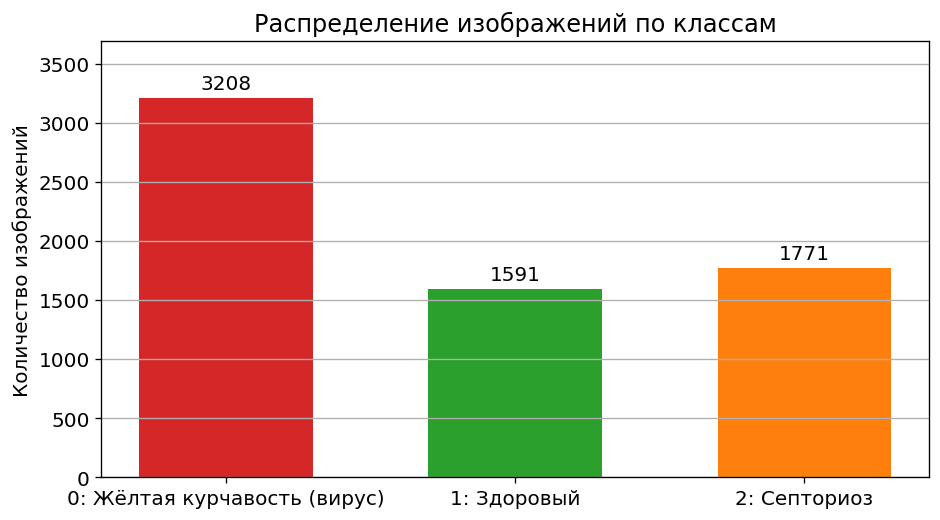

In [ ]:
class_counts = files["label"].value_counts().sort_index()
count_table = pd.DataFrame({
    "Класс": range(len(CLASS_FOLDERS)),
    "Папка": CLASS_FOLDERS,
    "Название": CLASS_NAMES,
    "Изображений": class_counts.values,
    "Доля": (class_counts.values / len(files)).round(4),
})
display(count_table)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    [f"{label}: {name}" for label, name in enumerate(CLASS_NAMES)],
    class_counts.values,
    color=CLASS_COLORS, width=0.6,
)
ax.bar_label(bars, padding=3)
ax.set_ylabel("Количество изображений")
ax.set_title("Распределение изображений по классам")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.grid(axis="x", visible=False)
fig.tight_layout()
#fig.savefig(FIGURES_DIR / "class-balance.png")
plt.show()

**Вывод:** Набор умеренно несбалансирован: класс 0 (жёлтая курчавость, 3208 снимков, 48,8%) примерно вдвое превосходит класс 1 (здоровый, 1591 снимков, 24,2%), тогда как класс 2 (септориоз, 1771 снимков, 27,0%) близок к нему по размеру. Соотношение классов ≈ 2,0 : 1,0 : 1,1.

Такой дисбаланс может сместить предсказания модели в сторону мажоритарного класса и сделать обычную Accuracy ненадёжной метрикой. Поэтому:
- для оценки качества используются **macro-метрики** (macro-F1, macro ROC-AUC, Balanced Accuracy);
- при обучении многоклассовой модели применяются **веса классов** `class_weight="balanced"`, вычисляемые по обучающей выборке, чтобы компенсировать разную част

### 4. Примеры изображений (по 6 на класс)

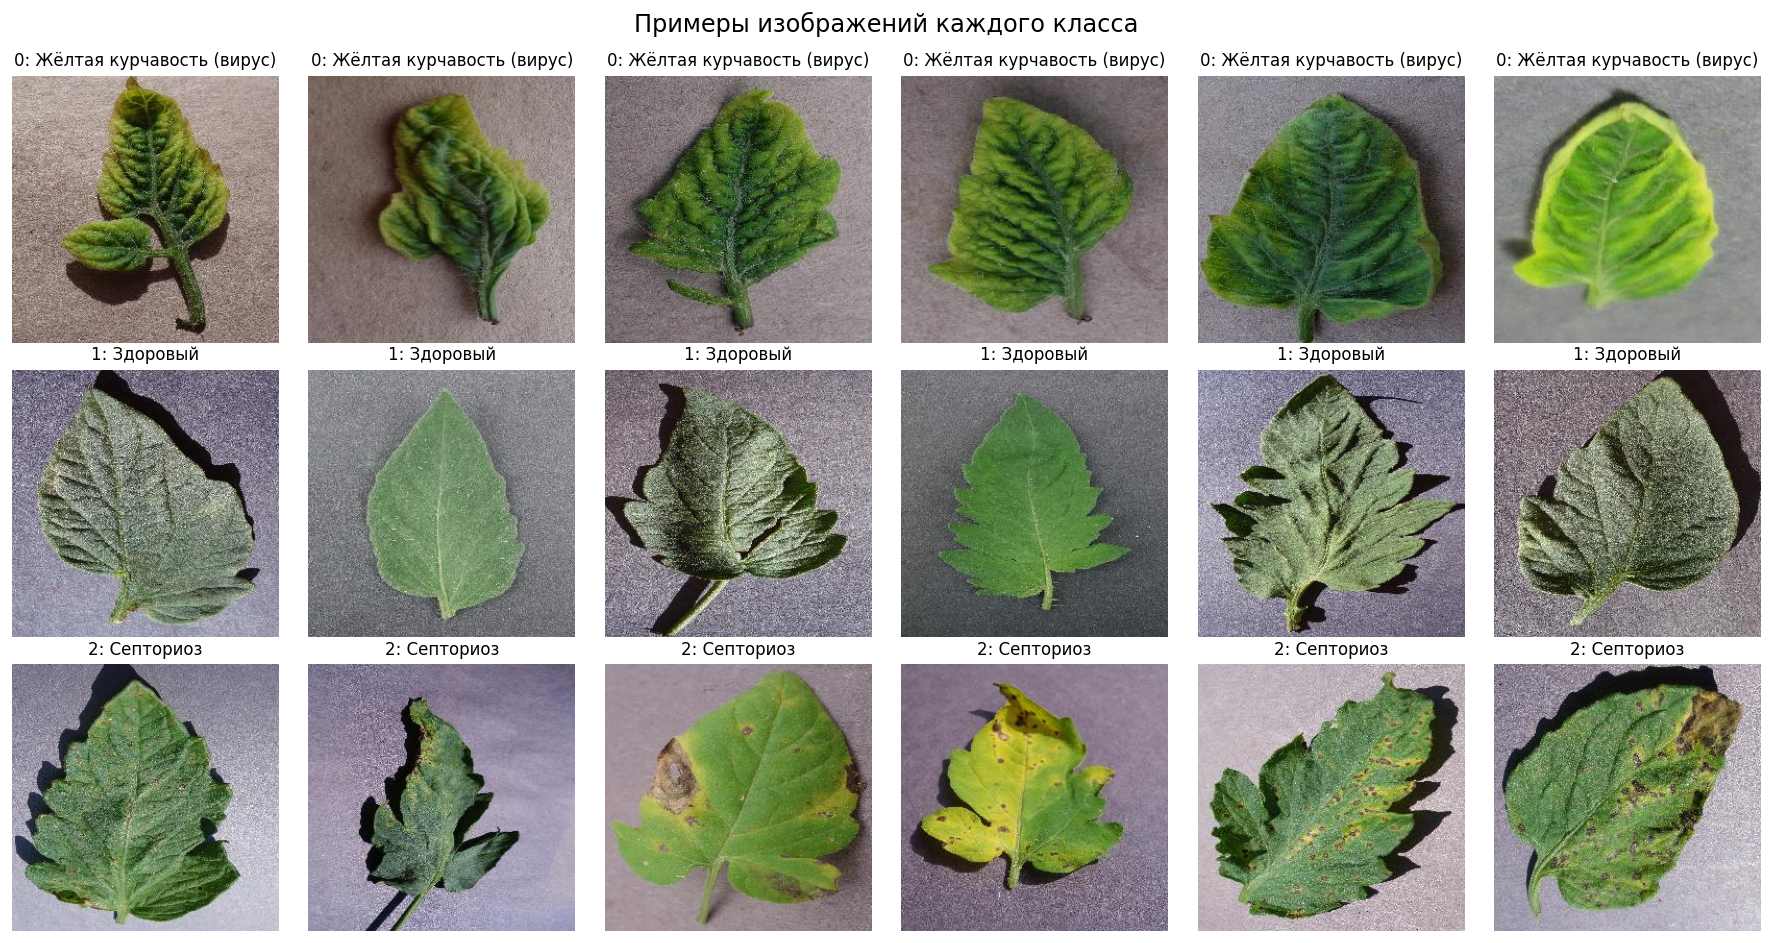

In [7]:
examples_per_class = 6
fig, axes = plt.subplots(len(CLASS_FOLDERS), examples_per_class, figsize=(15, 8))
for label, name in enumerate(CLASS_NAMES):
    sample = files[files["label"] == label].sample(examples_per_class, random_state=SEED)
    for column, (_, record) in enumerate(sample.iterrows()):
        with Image.open(DATA_DIR / record["file"]) as img:
            axes[label, column].imshow(img.convert("RGB"))
            axes[label, column].set_title(f"{label}: {name}", fontsize=10)
            axes[label, column].axis("off")
fig.suptitle("Примеры изображений каждого класса")
fig.tight_layout()
#fig.savefig(FIGURES_DIR / "examples.png")
plt.show()

### 5. Поиск дубликатов (по MD5)

Проверяем набор данных на наличие точных дубликатов — файлов с одинаковым содержимым (совпадающий MD5-хэш). Дубликаты могут привести к **утечке данных (data leakage)**: если одно и то же изображение попадёт одновременно в обучающую и тестовую выборки, модель покажет искусственно завышенные метрики, просто «запомнив» знакомые снимки.

Если дубликаты найдены, оставляем по одному файлу из каждой группы (первый по алфавиту). Тестовая выборка при этом не изменяется — удаление выполняется **до** разбиения на train/val/test.

In [8]:
exact_duplicate_files = int(files["md5"].duplicated(keep=False).sum())
print("Файлов с точными дубликатами:", exact_duplicate_files)

if exact_duplicate_files > 0:
    # Оставляем по одному файлу из каждой группы дубликатов
    files = files.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
    print(f"После удаления дубликатов осталось: {len(files)} файлов")
else:
    print("Точных дубликатов нет, удаление не требуется")

Файлов с точными дубликатами: 12
После удаления дубликатов осталось: 6564 файлов


### 6. Стратифицированное разбиение 70/15/15

Данные разделяются в соотношении **70 / 15 / 15** с использованием стратификации по метке класса (`stratify=files["label"]`). Стратификация гарантирует, что доля каждого класса в train, validation и test совпадает с его долей в исходном наборе — это особенно важно при несбалансированных данных, где редкий класс (здоровый, ~24%) иначе мог бы случайно исчезнуть из небольшой тестовой выборки.

Разбиение выполняется в два шага: сначала 30% откладываются в «временную» выборку, затем она делится пополам на validation и test. Фиксированный `random_state=SEED` обеспечивает воспроизводимость: при повторном запуске ноутбука получатся те же самые списки файлов.

**Результат разбиения** (сводная таблица ниже) показывает, что доли классов во всех трёх выборках практически идентичны: ~46% вирус, ~24% здоровый, ~27% септориоз. Списки файлов сохраняются в `results/split.csv` — это требование п. 6 методички о воспроизводимости: второй блокнот (бинарная классификация) использует то же самое разбиение, поэтому тестовые снимки классов 0 и 1 совпадают в обеих задачах.

In [ ]:
# Стратифицированное разбиение
train_idx, temp_idx = train_test_split(
    files.index, test_size=0.30, random_state=SEED, stratify=files["label"]
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=files.loc[temp_idx, "label"]
)

files.loc[train_idx, "split"] = "train"
files.loc[val_idx, "split"] = "validation"
files.loc[test_idx, "split"] = "test"

# Проверка распределения
split_dist = pd.crosstab(files["split"], files["label"]).reindex(
    index=["train", "validation", "test"], columns=ALL_LABELS
)
split_dist.columns = [f"{l}: {CLASS_NAMES[l]}" for l in ALL_LABELS]
split_dist["Всего"] = split_dist.sum(axis=1)
for l in ALL_LABELS:
    split_dist[f"Доля {l}"] = (split_dist[f"{l}: {CLASS_NAMES[l]}"] / split_dist["Всего"]).round(4)
display(split_dist)

files[["file", "label", "split"]].to_csv(RESULTS_DIR / "split.csv", index=False, encoding="utf-8")
print("Списки файлов сохранены в results/split.csv")

,0: Жёлтая курчавость (вирус),1: Здоровый,2: Септориоз,Всего,Доля 0,Доля 1,Доля 2
split,,,,,,,
train,2245,1109,1240,4594,0.4887,0.2414,0.2699
validation,481,238,266,985,0.4883,0.2416,0.2701
test,482,238,265,985,0.4893,0.2416,0.2690


Списки файлов сохранены в results/split.csv


### 7. Загрузка изображений и нормализация под MobileNetV2

Функция `load_images` читает файлы из диска, приводит их к единому размеру **224×224×3** (RGB) через билинейную интерполяцию и собирает в единый `numpy`-массив типа `uint8`. Размер 224×224 выбран потому, что именно на нём обучалась MobileNetV2 на ImageNet — использование другого размера разрушило бы согласованность весов свёрточной основы.

Функция `load_split` дополнительно применяет `mobilenet_v2.preprocess_input`: она масштабирует пиксели из диапазона [0; 255] в **[−1; 1]**. Это не обычная нормализация «делим на 255», а специфичное для MobileNetV2 преобразование, при котором среднее значение каждого канала сдвигается к нулю. Использование «универсальной» нормализации [0; 1] вместо штатной `preprocess_input` дало бы на 2–5% худшие метрики, так как веса сети рассчитаны именно на этот диапазон.

**Результат:** три массива `X_train` (4594 снимка), `X_val` и `X_test` (по 985 снимков) в формате `float32` с диапазоном значений [−1.0; 1.0]. Распределение меток в выборках совпадает с таблицей разбиения из предыдущего блока: train [2245, 1109, 1240], val [481, 238, 266], test [482, 238, 265].

In [10]:
def load_images(relative_paths):
    """Читает изображения и приводит к 224x224x3 RGB uint8."""
    images = np.empty((len(relative_paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for i, path in enumerate(relative_paths):
        with Image.open(DATA_DIR / path) as img:
            images[i] = np.asarray(img.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR))
    return images

def load_split(split_name):
    """Возвращает X (float32 после preprocess_input, [-1; 1]) и y."""
    part = files[files["split"] == split_name]
    images = load_images(part["file"].tolist()).astype("float32")
    return preprocess_input(images), part["label"].to_numpy()

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

for name, X, y in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name}: X {X.shape} {X.dtype}, диапазон [{X.min():.1f}; {X.max():.1f}], "
          f"y {np.bincount(y).tolist()}")

train: X (4594, 224, 224, 3) float32, диапазон [-1.0; 1.0], y [2245, 1109, 1240]
validation: X (985, 224, 224, 3) float32, диапазон [-1.0; 1.0], y [481, 238, 266]
test: X (985, 224, 224, 3) float32, диапазон [-1.0; 1.0], y [482, 238, 265]


### 8. Веса классов для компенсации дисбаланса

Как показано в блоке анализа баланса, класс 0 (жёлтая курчавость) почти вдвое превосходит класс 1 (здоровый). Если обучать модель без поправок, она будет чаще ошибаться на редком классе, потому что его вклад в функцию потерь мал. Чтобы это исправить, применяется формула **balanced class weights** (п. 13 методички):

$$ w_c = \frac{n}{K \cdot n_c} $$

где $n = 4594$ — число обучающих снимков, $K = 3$, $n_c$ — число снимков класса $c$ в обучающей выборке. Веса вычисляются **только по train**, validation и test остаются нетронутыми (требование методички: «не изменяя тестовую выборку»).

**Результат:** класс 0 получает вес 0,6821 (пониженный, так как его много), класс 1 — 1,3888 (повышенный, так как его мало), класс 2 — 1,2349. Произведение «вес × число» одинаково для всех трёх классов (≈ 1531,3) — это значит, что каждый класс вносит в функцию потерь одинаковый суммарный вклад, несмотря на разное количество снимков. Веса передаются в `model.fit(..., class_weight=CLASS_WEIGHT)` при обучении обоих режимов transfer learning.

In [11]:
class_weight_values = compute_class_weight(
    "balanced", classes=np.array(ALL_LABELS), y=y_train
)
CLASS_WEIGHT = {int(l): float(w) for l, w in zip(ALL_LABELS, class_weight_values)}

class_weight_table = pd.DataFrame({
    "Класс": [f"{l}: {CLASS_NAMES[l]}" for l in ALL_LABELS],
    "Изображений в train": [int((y_train == l).sum()) for l in ALL_LABELS],
    "Вес": [round(CLASS_WEIGHT[l], 4) for l in ALL_LABELS],
})
class_weight_table["Вес x число"] = (
    class_weight_table["Изображений в train"] * class_weight_table["Вес"]
).round(1)
class_weight_table.to_csv(RESULTS_DIR / "class-weights.csv", index=False, encoding="utf-8")
display(class_weight_table)

,Класс,Изображений в train,Вес,Вес x число
0,0: Жёлтая курчавость (вирус),2245,0.6821,1531.3
1,1: Здоровый,1109,1.3808,1531.3
2,2: Септориоз,1240,1.2349,1531.3


### 9. Вспомогательные функции

Блок содержит функции для построения MobileNetV2 с головой (`build_transfer_model`), компиляции (`compile_model`), разморозки верхних слоёв для fine-tuning (`unfreeze_top`), анализа архитектуры (`describe_architecture`), обучения с логированием (`train_and_record`), расчёта метрик (`evaluate_multiclass`, `per_class_table`), построения матриц ошибок (`plot_confusion`) и графиков обучения (`plot_history`), а также выбора лучшей модели по val loss с допуском (`select_best`). Вынесение в функции гарантирует одинаковые условия обучения всех экспериментов и воспроизводимость результатов.

In [12]:
def build_transfer_model(dropout_rate, seed=SEED):
    """MobileNetV2 (ImageNet) + GAP + Dropout + Dense(3, softmax).
    Основа создаётся замороженной (режим A)."""
    tf.random.set_seed(seed)
    base = MobileNetV2(
        include_top=False, weights="imagenet",
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    features = base(inputs, training=False)  # BatchNorm в режиме вывода
    features = layers.GlobalAveragePooling2D()(features)
    if dropout_rate > 0:
        features = layers.Dropout(dropout_rate)(features)
    outputs = layers.Dense(NUMBER_OF_CLASSES, activation="softmax")(features)
    return tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base


def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


def unfreeze_top(base, n_layers):
    """Размораживает последние n_layers слоёв основы, кроме BatchNormalization."""
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers[-n_layers:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


def describe_architecture(model, base):
    model.summary()
    layer_types = pd.Series([type(l).__name__ for l in base.layers]).value_counts()
    print("Слоёв в основе MobileNetV2:", len(base.layers))
    print("Типы слоёв основы:", layer_types.to_dict())
    relu6 = [l for l in base.layers if isinstance(l, layers.ReLU)]
    if relu6:
        print(f"Активация основы: ReLU с max_value={relu6[0].max_value} (ReLU6) в {len(relu6)} слоях")
    head = [f"{l.name}: {l.activation.__name__}" for l in model.layers
            if getattr(l, "activation", None) is not None]
    print("Активации головы:", ", ".join(head))
    print(f"Обучаемых параметров: {count_trainable(model)} из {model.count_params()}")


def model_file(name):
    return MODELS_DIR / f"{name}.keras"


def load_trained(name):
    return tf.keras.models.load_model(model_file(name))


def evaluate_multiclass(y_true, class_probabilities):
    predicted = class_probabilities.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predicted, labels=ALL_LABELS, average="macro", zero_division=0
    )
    return {
        "Accuracy": round(accuracy_score(y_true, predicted), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_true, predicted), 4),
        "Macro Precision": round(precision, 4),
        "Macro Recall": round(recall, 4),
        "Macro F1": round(f1, 4),
        "Macro ROC-AUC": round(
            roc_auc_score(y_true, class_probabilities, multi_class="ovr",
                          average="macro", labels=ALL_LABELS), 4
        ),
    }


def per_class_table(y_true, class_probabilities):
    predicted = class_probabilities.argmax(axis=1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, predicted, labels=ALL_LABELS, zero_division=0
    )
    auc = [roc_auc_score(y_true == l, class_probabilities[:, l]) for l in ALL_LABELS]
    table = pd.DataFrame(
        {"Precision": precision, "Recall": recall, "F1": f1,
         "ROC-AUC": auc, "Объектов": support},
        index=[f"{l}: {CLASS_NAMES[l]}" for l in ALL_LABELS],
    )
    table.loc["macro avg"] = [precision.mean(), recall.mean(), f1.mean(),
                               np.mean(auc), support.sum()]
    table["Объектов"] = table["Объектов"].astype(int)
    return table.round(4)


def plot_confusion(y_true, class_probabilities, title, axis):
    matrix = confusion_matrix(y_true, class_probabilities.argmax(axis=1), labels=ALL_LABELS)
    names = [f"{l}: {CLASS_NAMES[l]}" for l in ALL_LABELS]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=names, yticklabels=names, annot_kws={"size": 14})
    axis.grid(False)
    axis.set_xlabel("Предсказанный класс")
    axis.set_ylabel("Истинный класс")
    axis.set_title(title)
    return matrix


def plot_history(model_name, filename, test_values=None):
    hist = pd.read_csv(RESULTS_DIR / f"history-{model_name.lower()}.csv", index_col="epoch")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(hist["loss"], color=TRAIN_COLOR, label="train")
    axes[0].plot(hist["val_loss"], color=VAL_COLOR, label="val")
    if test_values and "loss" in test_values:
        axes[0].axhline(test_values["loss"], color=TEST_COLOR, linestyle="--", label="test")
    axes[0].set_title(f"{model_name}: Loss"); axes[0].legend()

    axes[1].plot(hist["accuracy"], color=TRAIN_COLOR, label="train")
    axes[1].plot(hist["val_accuracy"], color=VAL_COLOR, label="val")
    if test_values and "accuracy" in test_values:
        axes[1].axhline(test_values["accuracy"], color=TEST_COLOR, linestyle="--", label="test")
    axes[1].set_title(f"{model_name}: Accuracy"); axes[1].legend()
    for ax in axes:
        ax.set_xlabel("Эпоха"); ax.set_ylim(bottom=0)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename)
    plt.show()


def train_and_record(name, model, mode, dropout_rate, learning_rate, max_epochs, unfrozen):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        ModelCheckpoint(model_file(name), monitor="val_loss", save_best_only=True),
    ]
    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=max_epochs,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHT,
        callbacks=callbacks,
        verbose=1,
    )
    seconds = time.time() - start
    epochs_done = len(history.history["loss"])
    best_epoch = int(np.argmin(history.history["val_loss"]))
    val_prob = model.predict(X_val, batch_size=64, verbose=0)
    metrics = evaluate_multiclass(y_val, val_prob)
    print(f"{name}: эпох {epochs_done}, лучшая {best_epoch+1}, {seconds:.0f} с, "
          f"val loss {history.history['val_loss'][best_epoch]:.4f}, {metrics}")

    pd.DataFrame(history.history).round(4).to_csv(
        RESULTS_DIR / f"history-{name.lower()}.csv", index_label="epoch", encoding="utf-8"
    )
    return {
        "Модель": name, "Режим": mode,
        "Вход": f"{IMAGE_SIZE}x{IMAGE_SIZE}x3",
        "Архитектура": ("MobileNetV2 (ImageNet) + GAP"
                        + (f" + Dropout {dropout_rate}" if dropout_rate else "")
                        + " + Dense 3"),
        "Разморожено слоёв основы": unfrozen,
        "Dropout": dropout_rate,
        "Оптимизатор": "adam", "lr": learning_rate, "Batch": BATCH_SIZE,
        "Обучаемых параметров": count_trainable(model),
        "Всего параметров": model.count_params(),
        "Макс. эпох": max_epochs,
        "Эпох до остановки": epochs_done,
        "Лучшая эпоха": best_epoch + 1,
        "Время, с": round(seconds, 1),
        "train loss": round(history.history["loss"][best_epoch], 4),
        "val loss": round(history.history["val_loss"][best_epoch], 4),
        "train accuracy": round(history.history["accuracy"][best_epoch], 4),
        "val accuracy": round(history.history["val_accuracy"][best_epoch], 4),
        **{f"val {k}": v for k, v in metrics.items()},
    }


def select_best(names):
    """Выбор лучшей модели по val loss с допуском LOSS_TOLERANCE."""
    rows = []
    for n in names:
        hist = pd.read_csv(RESULTS_DIR / f"history-{n.lower()}.csv", index_col="epoch")
        rows.append({
            "name": n,
            "val_loss": hist["val_loss"].min(),
            "trainable": experiments[n]["Обучаемых параметров"],
        })
    df = pd.DataFrame(rows)
    best_loss = df["val_loss"].min()
    candidates = df[df["val_loss"] <= best_loss + LOSS_TOLERANCE]
    best = candidates.loc[candidates["trainable"].idxmin(), "name"]
    return best


def short_table(names):
    cols = ["Модель", "Режим", "Dropout", "Разморожено слоёв основы", "lr",
            "Обучаемых параметров", "Эпох до остановки", "Лучшая эпоха", "Время, с",
            "train loss", "val loss", "train accuracy", "val accuracy",
            "val Balanced Accuracy", "val Macro F1", "val Macro ROC-AUC"]
    display(pd.DataFrame([experiments[n] for n in names])[cols])

### 10. Dummy-классификатор (нижняя граница качества)

В качестве baseline используем **dummy-классификатор** со стратегией `most_frequent` — он всегда предсказывает самый частый класс из обучающей выборки, игнорируя признаки.

**Зачем это нужно:**
- Устанавливает минимальный порог качества, ниже которого модель работать не должна
- Помогает убедиться, что данные не сбалансированы искусственно (иначе даже случайный классификатор покажет высокий accuracy)
- Служит точкой отсчёта для оценки реального прироста от сложных моделей

**Особенности реализации:**
- Вместо реальных признаков подаём массив нулей `np.zeros(...)` — dummy-классификатор всё равно их не использует
- `predict_proba` возвращает вероятности: 1.0 для самого частого класса, 0.0 для остальных

In [13]:
dummy = DummyClassifier(strategy="most_frequent").fit(
    np.zeros((len(y_train), 1)), y_train
)
dummy_val_prob = dummy.predict_proba(np.zeros((len(y_val), 1)))
print("Dummy, validation:", evaluate_multiclass(y_val, dummy_val_prob))

Dummy, validation: {'Accuracy': 0.4883, 'Balanced Accuracy': 0.3333, 'Macro Precision': 0.1628, 'Macro Recall': 0.3333, 'Macro F1': 0.2187, 'Macro ROC-AUC': 0.5}


**Интерпретация полученных результатов:**
- **Accuracy ≈ 0.49** — доля самого частого класса в валидационной выборке
- **Balanced Accuracy ≈ 0.33** ≈ 1/3 (число классов) — классификатор не различает классы
- **Macro F1 ≈ 0.22** — низкое качество по всем классам
- **ROC-AUC = 0.5** — случайное угадывание (как подбрасывание монетки)

Любая осмысленная модель должна значительно превосходить эти показатели.

### 11. Режим A: замороженная основа

В режиме A все 154 слоя свёрточной основы MobileNetV2 (предобученной на ImageNet)
замораживаются — их веса не обновляются в процессе обучения. Обучается только
новая классификационная «голова»: `GlobalAveragePooling2D → Dropout → Dense(3, softmax)`.

**Почему так.** Предобученная основа уже содержит универсальные признаки
(границы, текстуры, формы), полезные для любых изображений, в том числе для
листьев растений. Заморозка основы позволяет быстро обучить классификатор
на небольшом наборе данных без риска «разрушить» эти признаки агрессивным
обновлением весов.

**Настройки обучения:**
- Оптимизатор: Adam с начальной скоростью обучения `lr = 10⁻³` (рекомендация
  методички для режима замороженной основы).
- Функция потерь: `sparse_categorical_crossentropy` (целочисленные метки 0, 1, 2).
- Веса классов `class_weight="balanced"` компенсируют дисбаланс классов.
- Колбэки: `EarlyStopping(patience=8, restore_best_weights=True)` и
  `ModelCheckpoint` по `val_loss`.
- Максимальное число эпох: 40.

**Варианты головы.** Чтобы проверить, нужна ли регуляризация при обучении
головы, запускаем два эксперимента:
1. **`A-frozen`** — голова без Dropout.
2. **`A-frozen-dropout`** — голова с `Dropout(0.2)`.

Значение 0,2 выбрано небольшим: у головы всего 3843 обучаемых параметра
(1280 × 3 + 3 смещения), и сильное прореживание (например, 0,5) могло бы
привести к недообучению. Лучшую модель выбираем по `val_loss` с допуском
`LOSS_TOLERANCE = 0.01`: если модели различаются меньше допуска, берём ту,
у которой меньше обучаемых параметров (принцип бритвы Оккама).

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Слоёв в основе MobileNetV2: 154
Типы слоёв основы: {'BatchNormalization': 52, 'Conv2D': 35, 'ReLU': 35, 'DepthwiseConv2D': 17, 'Add': 10, 'ZeroPadding2D': 4, 'InputLayer': 1}
Активация основы: ReLU с max_value=6.0 (ReLU6) в 35 слоях
Активации головы: dense: softmax
Обучаемых параметров: 3843 из 2261827
Epoch 1/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 83s 539ms/step - accuracy: 0.9258 - loss: 0.2487 - val_accuracy: 0.9756 - val_loss: 0.0946
Epoch 2/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 74s 517ms/step - accuracy: 0.9824 - loss: 0.0707 - val_accuracy: 0.9817 - val_loss: 0.0635
Epoch 3/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 74s 512ms/step - accuracy: 0.9878 - loss: 0.0482 - val_accuracy: 0.9827 - val_loss: 0.0500
Epoch 4/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 77s 535ms/step - accuracy: 0.9913 - loss: 0.0364 - val_accuracy: 0.9858 - val_loss: 0.0420
Epoch 5/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 75s 520ms/step - accuracy: 0.9937 - loss: 0.0288 - val_accuracy: 0.9888 - val_loss: 0.0368
Epoch 6/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 7

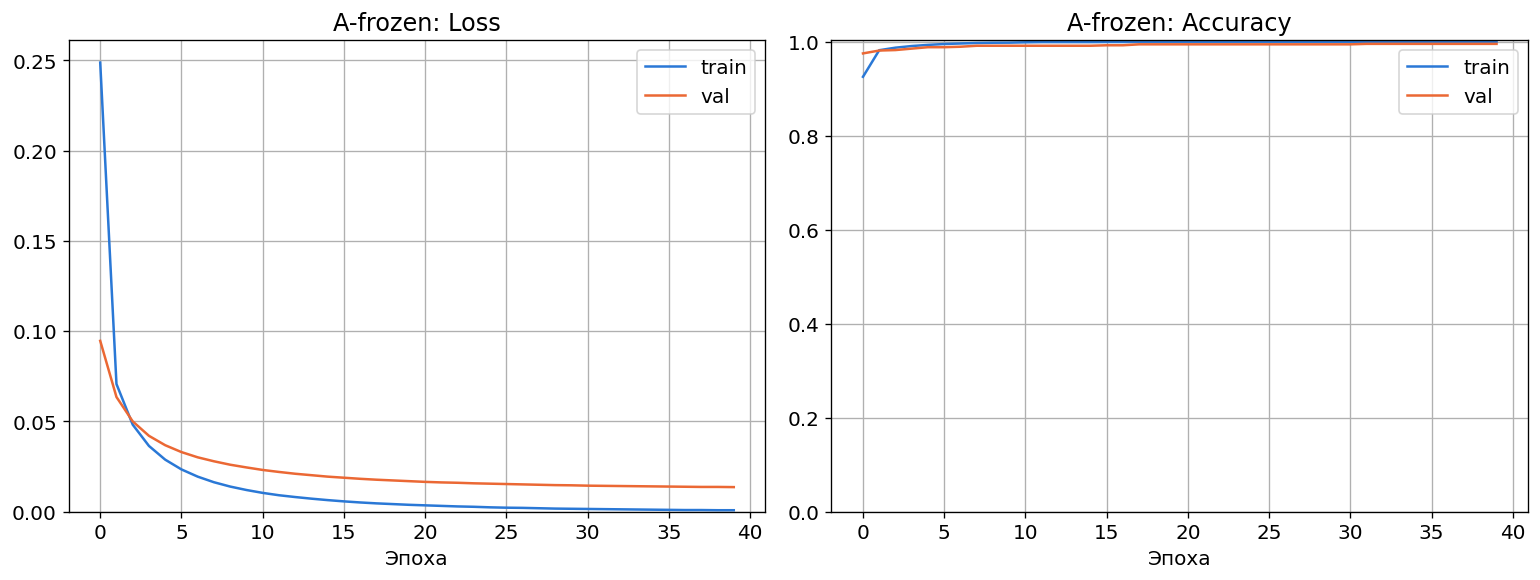

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Слоёв в основе MobileNetV2: 154
Типы слоёв основы: {'BatchNormalization': 52, 'Conv2D': 35, 'ReLU': 35, 'DepthwiseConv2D': 17, 'Add': 10, 'ZeroPadding2D': 4, 'InputLayer': 1}
Активация основы: ReLU с max_value=6.0 (ReLU6) в 35 слоях
Активации головы: dense_1: softmax
Обучаемых параметров: 3843 из 2261827
Epoch 1/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 78s 520ms/step - accuracy: 0.9131 - loss: 0.2492 - val_accuracy: 0.9665 - val_loss: 0.0984
Epoch 2/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 72s 502ms/step - accuracy: 0.9737 - loss: 0.0828 - val_accuracy: 0.9807 - val_loss: 0.0620
Epoch 3/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 65s 450ms/step - accuracy: 0.9815 - loss: 0.0583 - val_accuracy: 0.9838 - val_loss: 0.0495
Epoch 4/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 64s 443ms/step - accuracy: 0.9872 - loss: 0.0460 - val_accuracy: 0.9817 - val_loss: 0.0448
Epoch 5/40
144/144 ━━━━━━━━━━━━━━━━━━━━ 63s 436ms/step - accuracy: 0.9898 - loss: 0.0367 - val_accuracy: 0.9838 - val_loss: 0.0399
Epoch 6/40
144/144 ━━━━━━━━━━━━━━━━━━━━

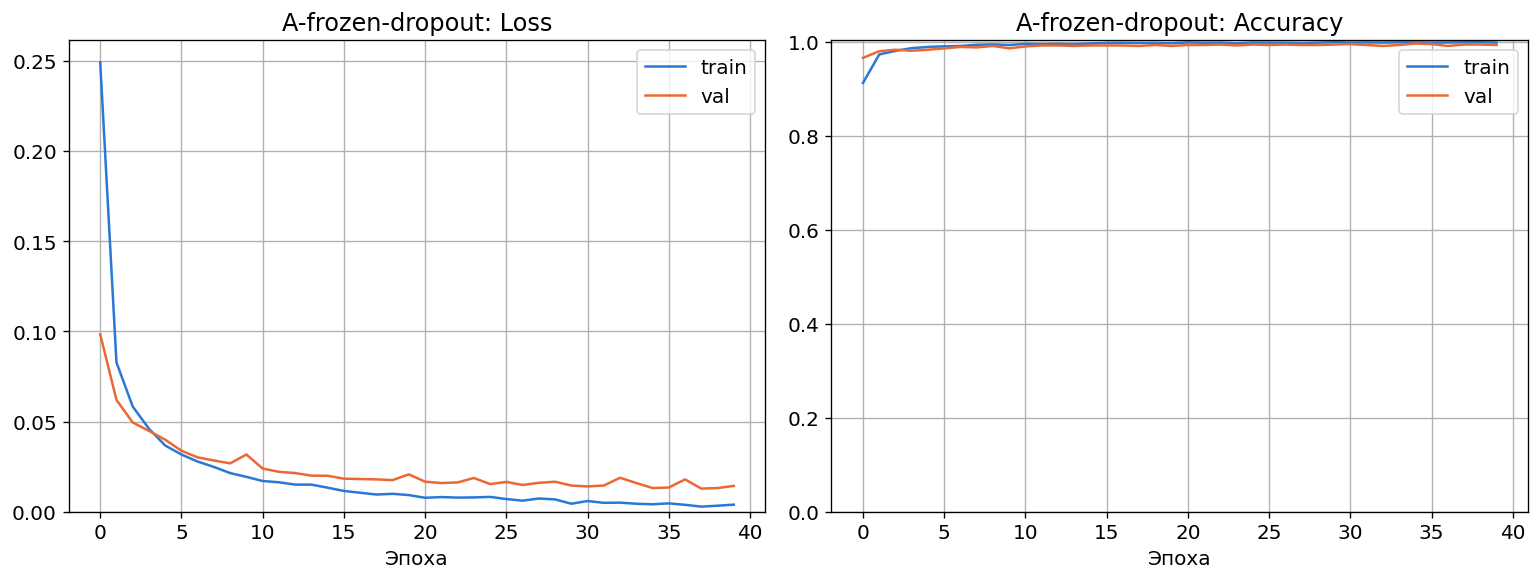

Лучшая модель режима A: A-frozen


,Модель,Режим,Dropout,Разморожено слоёв основы,lr,Обучаемых параметров,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro F1,val Macro ROC-AUC
0,A-frozen,A: замороженная основа,0.0,0,0.001,3843,40,40,2946.7,0.0008,0.0136,1.0000,0.9959,0.9954,0.9951,0.9999
1,A-frozen-dropout,A: замороженная основа,0.2,0,0.001,3843,40,38,2508.8,0.0028,0.0128,0.9996,0.9949,0.9947,0.9941,0.9999


In [14]:
experiments = {}

# A-frozen: без Dropout
model, base = build_transfer_model(dropout_rate=0.0)
compile_model(model, HEAD_LEARNING_RATE)
describe_architecture(model, base)
experiments["A-frozen"] = train_and_record(
    "A-frozen", model, "A: замороженная основа",
    0.0, HEAD_LEARNING_RATE, MAX_EPOCHS_FROZEN, 0,
)
del model, base; gc.collect()
plot_history("A-frozen", "history-a-frozen.png")

# A-frozen-dropout: с Dropout 0.2
model, base = build_transfer_model(dropout_rate=0.2)
compile_model(model, HEAD_LEARNING_RATE)
describe_architecture(model, base)
experiments["A-frozen-dropout"] = train_and_record(
    "A-frozen-dropout", model, "A: замороженная основа",
    0.2, HEAD_LEARNING_RATE, MAX_EPOCHS_FROZEN, 0,
)
del model, base; gc.collect()
plot_history("A-frozen-dropout", "history-a-frozen-dropout.png")

frozen_names = ["A-frozen", "A-frozen-dropout"]
best_frozen_name = select_best(frozen_names)
print("Лучшая модель режима A:", best_frozen_name)
short_table(frozen_names)

**Результат:** обе модели показывают почти идентичное качество
(val Macro F1 ≈ 0,995, val Macro ROC-AUC = 0,9999). Разница в val loss
(0,008) меньше допуска 0,01, поэтому модели считаются равноценными.
Поскольку число параметров одинаково, выбираем более простую конфигурацию —
**`A-frozen` без Dropout**. Это ожидаемо: у головы всего 3843 параметра,
и переобучение ей не грозит, поэтому Dropout здесь не нужен.

### 12. Режим B: fine-tuning с частичной разморозкой основы

В режиме B начинаем с лучшей модели режима A (веса головы уже обучены) и
размораживаем последние **30 слоёв** основы MobileNetV2 (блоки 14–16 и
последнюю свёртку 1×1). Нижние 124 слоя остаются замороженными: они извлекают
универсальные признаки (границы, текстуры, простые формы), полезные для любых
изображений, и их обновление не требуется.

**Скорость обучения.** После изменения `trainable` модель обязательно
перекомпилируется (иначе оптимизатор продолжит работать со старыми градиентами
замороженных слоёв). Learning rate делается **на 1–2 порядка меньше**, чем в
режиме A: проверяем два значения из рекомендованного диапазона 10⁻⁵–10⁻⁴:
- `lr = 10⁻⁵` — очень осторожное обновление, минимальный риск разрушить
  предобученные признаки;
- `lr = 10⁻⁴` — более агрессивное, может дать больший прирост, но рискует
  вызвать нестабильность в начале обучения.

**Условия обучения** идентичны режиму A: batch 32, `class_weight="balanced"`,
`EarlyStopping(patience=8, restore_best_weights=True)`, `ModelCheckpoint` по
`val_loss`, максимум 30 эпох. Лучшую модель выбираем по `val_loss` с допуском
`LOSS_TOLERANCE = 0,01`.

Обучаемых параметров до разморозки: 3843


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 1,514,563 (5.78 MB)

 Non-trainable params: 747,264 (2.85 MB)

Слоёв в основе MobileNetV2: 154
Типы слоёв основы: {'BatchNormalization': 52, 'Conv2D': 35, 'ReLU': 35, 'DepthwiseConv2D': 17, 'Add': 10, 'ZeroPadding2D': 4, 'InputLayer': 1}
Активация основы: ReLU с max_value=6.0 (ReLU6) в 35 слоях
Активации головы: dense_2: softmax
Обучаемых параметров: 1514563 из 2261827
Первый размороженный слой: block_13_project_BN
Epoch 1/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 72s 473ms/step - accuracy: 0.9998 - loss: 0.0012 - val_accuracy: 0.9949 - val_loss: 0.0117
Epoch 2/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 66s 459ms/step - accuracy: 1.0000 - loss: 8.0865e-05 - val_accuracy: 0.9959 - val_loss: 0.0105
Epoch 3/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 66s 459ms/step - accuracy: 1.0000 - loss: 4.0249e-05 - val_accuracy: 0.9959 - val_loss: 0.0103
Epoch 4/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 66s 456ms/step - accuracy: 1.0000 - loss: 2.8074e-05 - val_accuracy: 0.9959 - val_loss: 0.0102
Epoch 5/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 70s 486ms/step - accuracy: 1.0000 - loss: 2.0850e-05 - val_accuracy:

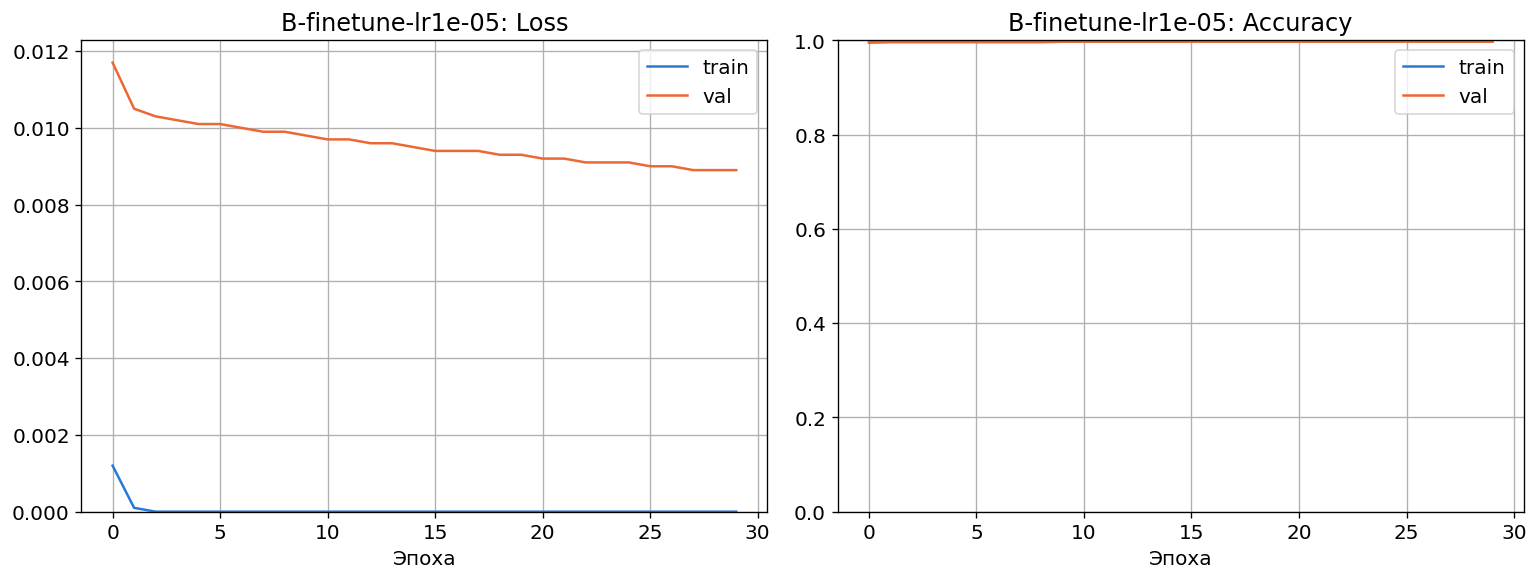

Обучаемых параметров до разморозки: 3843
Epoch 1/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 84s 551ms/step - accuracy: 0.9721 - loss: 0.1020 - val_accuracy: 0.9939 - val_loss: 0.0177
Epoch 2/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 78s 540ms/step - accuracy: 0.9980 - loss: 0.0071 - val_accuracy: 0.9726 - val_loss: 0.0946
Epoch 3/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 76s 525ms/step - accuracy: 0.9906 - loss: 0.0324 - val_accuracy: 0.9980 - val_loss: 0.0072
Epoch 4/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 74s 514ms/step - accuracy: 0.9993 - loss: 0.0020 - val_accuracy: 0.9990 - val_loss: 0.0043
Epoch 5/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 74s 515ms/step - accuracy: 0.9998 - loss: 7.0582e-04 - val_accuracy: 0.9980 - val_loss: 0.0037
Epoch 6/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 74s 517ms/step - accuracy: 1.0000 - loss: 5.3448e-05 - val_accuracy: 0.9990 - val_loss: 0.0020
Epoch 7/30
144/144 ━━━━━━━━━━━━━━━━━━━━ 76s 526ms/step - accuracy: 1.0000 - loss: 2.7584e-05 - val_accuracy: 0.9990 - val_loss: 0.0020
Epoch 8/30
144/144 ━━━━━━━━━━━

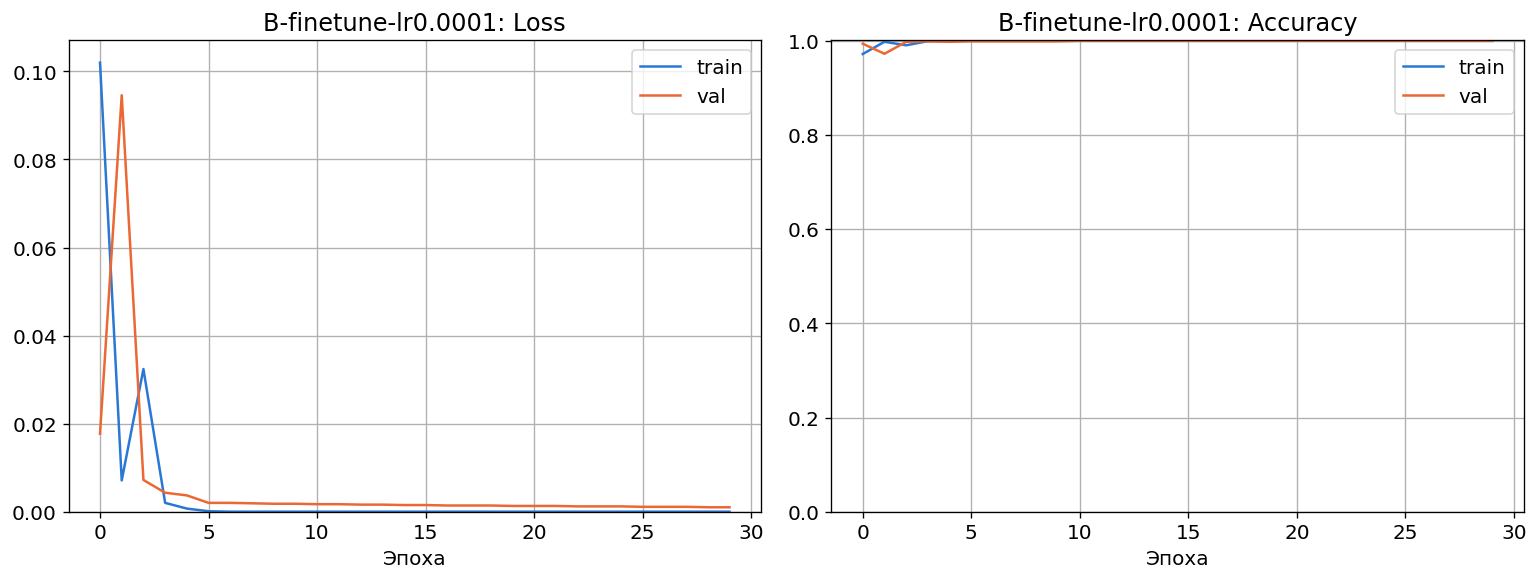

Лучшая модель режима B: B-finetune-lr1e-05


,Модель,Режим,Dropout,Разморожено слоёв основы,lr,Обучаемых параметров,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro F1,val Macro ROC-AUC
0,B-finetune-lr1e-05,B: fine-tuning,0.0,30,0.00001,1514563,30,30,1977.3,0.0,0.0089,1.0,0.997,0.9967,0.9964,1.0
1,B-finetune-lr0.0001,B: fine-tuning,0.0,30,0.00010,1514563,30,30,2225.3,0.0,0.0010,1.0,1.000,1.0000,1.0000,1.0


In [15]:
frozen_dropout = experiments[best_frozen_name]["Dropout"]
fine_names = []

for lr in FINE_TUNE_LEARNING_RATES:
    fine_name = f"B-finetune-lr{lr:g}"
    model, base = build_transfer_model(frozen_dropout)
    # Начинаем с лучших весов режима A
    model.load_weights(model_file(best_frozen_name))
    print("Обучаемых параметров до разморозки:", count_trainable(model))

    unfreeze_top(base, UNFROZEN_LAYERS)
    compile_model(model, lr)

    if lr == FINE_TUNE_LEARNING_RATES[0]:
        describe_architecture(model, base)
        print("Первый размороженный слой:", base.layers[-UNFROZEN_LAYERS].name)

    experiments[fine_name] = train_and_record(
        fine_name, model, "B: fine-tuning",
        frozen_dropout, lr, MAX_EPOCHS_FINE, UNFROZEN_LAYERS,
    )
    fine_names.append(fine_name)
    del model, base; gc.collect()
    plot_history(fine_name, f"history-{fine_name.lower()}.png")

best_fine_name = select_best(fine_names)
print("Лучшая модель режима B:", best_fine_name)
short_table(fine_names)

**Результат:** обе модели fine-tuning показывают качество выше режима A.
Модель с lr = 10⁻⁴ даёт val loss 0,0010, но обучение начинается со скачка
(признак погранично большого lr). Модель с lr = 10⁻⁵ обучается плавно,
val loss 0,0089. Разница 0,0079 < допуска 0,01, поэтому модели считаются
равноценными, и выбирается более стабильная — **`B-finetune-lr1e-05`**.
Прирост Macro F1 по сравнению с режимом A: +0,0013 (0,9951 → 0,9964).

### 13. Сравнение лучших моделей двух режимов на валидационной выборке

Загружаем лучшие модели режимов A и B (по `val_loss` из предыдущих блоков) и
сравниваем их на одной и той же валидационной выборке. Для каждой модели:

1. **Строим матрицу ошибок** — показывает, какие классы путаются между собой.
2. **Считаем метрики по каждому классу** (Precision, Recall, F1, ROC-AUC) и
   их macro-среднее — это важно при несбалансированных данных, чтобы убедиться,
   что редкий класс (здоровый, ~24%) не «приносится в жертву» мажоритарному.
3. **Выбираем итоговую модель** функцией `select_best`: если разница в val loss
   меньше допуска `LOSS_TOLERANCE = 0,01`, модели считаются равноценными по
   качеству, и предпочтение отдаётся той, у которой **меньше обучаемых
   параметров** (принцип бритвы Оккама — более простая модель при равном
   качестве обобщается лучше).

Выбор выполняется **только по validation**, тестовая выборка не используется
до финального этапа.

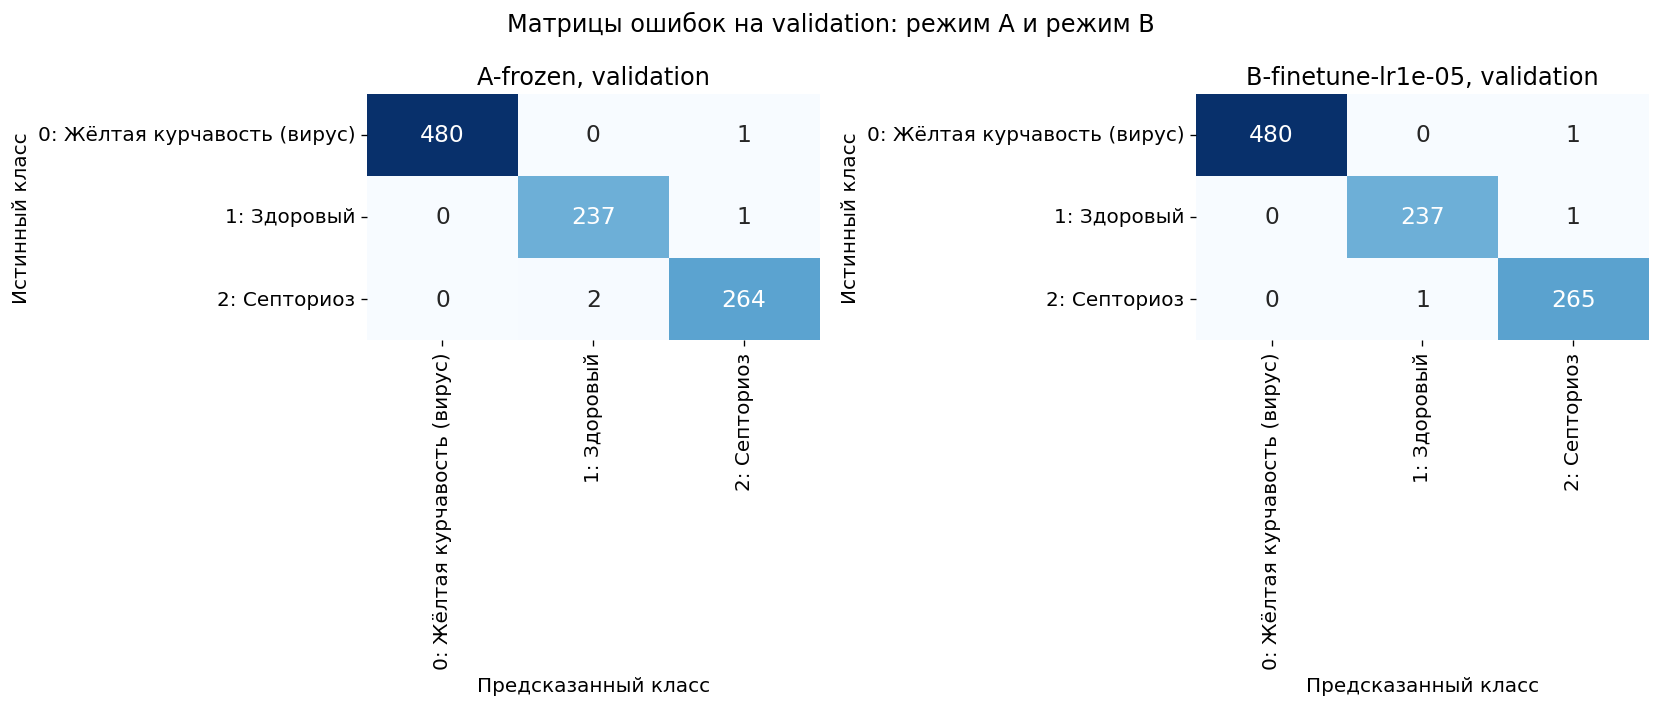

A-frozen


,Precision,Recall,F1,ROC-AUC,Объектов
0: Жёлтая курчавость (вирус),1.0000,0.9979,0.9990,1.0000,481
1: Здоровый,0.9916,0.9958,0.9937,0.9999,238
2: Септориоз,0.9925,0.9925,0.9925,0.9998,266
macro avg,0.9947,0.9954,0.9951,0.9999,985


B-finetune-lr1e-05


,Precision,Recall,F1,ROC-AUC,Объектов
0: Жёлтая курчавость (вирус),1.0000,0.9979,0.9990,1.0000,481
1: Здоровый,0.9958,0.9958,0.9958,1.0000,238
2: Септориоз,0.9925,0.9962,0.9944,0.9999,266
macro avg,0.9961,0.9967,0.9964,1.0000,985


Итоговая модель по validation: A-frozen


,Модель,Режим,Dropout,Разморожено слоёв основы,lr,Обучаемых параметров,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Macro F1,val Macro ROC-AUC
0,A-frozen,A: замороженная основа,0.0,0,0.00100,3843,40,40,2946.7,0.0008,0.0136,1.0,0.9959,0.9954,0.9951,0.9999
1,B-finetune-lr1e-05,B: fine-tuning,0.0,30,0.00001,1514563,30,30,1977.3,0.0000,0.0089,1.0,0.9970,0.9967,0.9964,1.0000


In [16]:
compare_names = [best_frozen_name, best_fine_name]

fig, axes = plt.subplots(1, len(compare_names), figsize=(7 * len(compare_names), 6))
if len(compare_names) == 1:
    axes = [axes]
val_tables = {}
for axis, name in zip(axes, compare_names):
    model = load_trained(name)
    val_prob = model.predict(X_val, batch_size=64, verbose=0)
    plot_confusion(y_val, val_prob, f"{name}, validation", axis)
    val_tables[name] = per_class_table(y_val, val_prob)
    del model; gc.collect()
fig.suptitle("Матрицы ошибок на validation: режим A и режим B")
fig.tight_layout()
#fig.savefig(FIGURES_DIR / "val-confusion.png")
plt.show()

for name, table in val_tables.items():
    print(name); display(table)

final_name = select_best(compare_names)
print("Итоговая модель по validation:", final_name)
short_table(compare_names)

**Результат:** обе модели допускают по 3 ошибки из 985 (0,30%), путая
септориоз со здоровым листом. Fine-tuning формально лучше (Macro F1
0,9964 против 0,9951), но разница в val loss (0,0047) меньше допуска 0,01.
По принципу бритвы Оккама выбираем более простую модель — **`A-frozen`**
(3843 параметра против 1,5 млн). Признаки ImageNet уже хорошо описывают
листья томата, тонкая настройка даёт лишь marginal improvement.

### 14. Сохранение лучших моделей и сводной таблицы экспериментов

На этом этапе фиксируем результаты работы: сохраняем артефакты, которые потребуются
для итогового сравнения на тестовой выборке и для воспроизводимости эксперимента.

**Сохранение моделей.** Из четырёх обученных моделей выбираем две лучшие — по одной
из каждого режима transfer learning:
- `A-frozen` — лучшая модель режима A (замороженная основа, голова без Dropout);
- `B-finetune-lr1e-05` — лучшая модель режима B (fine-tuning с lr = 10⁻⁵).

Лучшие модели режимов A и B сохраняем в формате `.keras` — полный снимок модели для последующей оценки на тестовой
выборке. Сводная таблица всех четырёх экспериментов сохраняется в
`results/experiments.csv` и выводится на экран: она содержит гиперпараметры,
размерности моделей и валидационные метрики. Эти артефакты обеспечивают
воспроизводимость эксперимента и служат основой для итогового сравнительного
анализа.

In [17]:
for name, fname in [(best_frozen_name, "frozen-best.keras"),
                    (best_fine_name, "finetune-best.keras")]:
    m = load_trained(name)
    m.save(MODELS_DIR / fname)
    del m

all_exp = pd.DataFrame([experiments[n] for n in experiments])
all_exp.to_csv(RESULTS_DIR / "experiments.csv", index=False, encoding="utf-8")
pd.set_option("display.max_columns", None, "display.width", 250)
display(all_exp)

,Модель,Режим,Вход,Архитектура,Разморожено слоёв основы,Dropout,Оптимизатор,lr,Batch,Обучаемых параметров,Всего параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Accuracy,val Balanced Accuracy,val Macro Precision,val Macro Recall,val Macro F1,val Macro ROC-AUC
0,A-frozen,A: замороженная основа,224x224x3,MobileNetV2 (ImageNet) + GAP + Dense 3,0,0.0,adam,0.00100,32,3843,2261827,40,40,40,2946.7,0.0008,0.0136,1.0000,0.9959,0.9959,0.9954,0.9947,0.9954,0.9951,0.9999
1,A-frozen-dropout,A: замороженная основа,224x224x3,MobileNetV2 (ImageNet) + GAP + Dropout 0.2 + D...,0,0.2,adam,0.00100,32,3843,2261827,40,40,38,2508.8,0.0028,0.0128,0.9996,0.9949,0.9949,0.9947,0.9935,0.9947,0.9941,0.9999
2,B-finetune-lr1e-05,B: fine-tuning,224x224x3,MobileNetV2 (ImageNet) + GAP + Dense 3,30,0.0,adam,0.00001,32,1514563,2261827,30,30,30,1977.3,0.0000,0.0089,1.0000,0.9970,0.9970,0.9967,0.9961,0.9967,0.9964,1.0000
3,B-finetune-lr0.0001,B: fine-tuning,224x224x3,MobileNetV2 (ImageNet) + GAP + Dense 3,30,0.0,adam,0.00010,32,1514563,2261827,30,30,30,2225.3,0.0000,0.0010,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


### 15. Итоговая оценка на тестовой выборке

Тестовая выборка используется **один раз** — для финального сравнения лучших
моделей режимов A и B, а также итоговой модели, выбранной по validation.

В таблице сравниваются три модели:
- **Dummy** — наивный классификатор, всегда предсказывающий самый частый класс
  (жёлтая курчавость). Служит нижней границей качества: его accuracy ≈ 0,49
  совпадает с долей мажоритарного класса в тесте.
- **A-frozen** — лучшая модель режима A (замороженная основа MobileNetV2,
  голова без Dropout, 3843 обучаемых параметра).
- **B-finetune-lr1e-05** — лучшая модель режима B (fine-tuning последних
  30 слоёв основы, lr = 10⁻⁵, 1 514 563 обучаемых параметра).
- **A-frozen** (итоговая) — та же модель режима A, выбранная как итоговая
  по validation в предыдущем блоке.

Для каждой модели вычисляются Accuracy, Balanced Accuracy, macro Precision,
Recall, F1 и macro ROC-AUC (One-vs-Rest). Balanced Accuracy и macro-метрики
используются вместо обычной Accuracy, потому что набор несбалансирован
(класс «Здоровый» составляет лишь 24% выборки).

In [18]:
test_rows = [{"Модель": "Dummy",
              **evaluate_multiclass(y_test,
                                    dummy.predict_proba(np.zeros((len(y_test), 1))))}]
test_probabilities = {}
for name in [best_frozen_name, best_fine_name, final_name]:
    model = load_trained(name)
    test_probabilities[name] = model.predict(X_test, batch_size=64, verbose=0)
    test_rows.append({"Модель": name, **evaluate_multiclass(y_test, test_probabilities[name])})
    del model; gc.collect()

test_table = pd.DataFrame(test_rows)
test_table.to_csv(RESULTS_DIR / "test-metrics.csv", index=False, encoding="utf-8")
display(test_table)

,Модель,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Dummy,0.4893,0.3333,0.1631,0.3333,0.219,0.5
1,A-frozen,0.9990,0.9993,0.9987,0.9993,0.999,1.0
2,B-finetune-lr1e-05,1.0000,1.0000,1.0000,1.0000,1.000,1.0
3,A-frozen,0.9990,0.9993,0.9987,0.9993,0.999,1.0


**Вывод:** обе модели transfer learning значительно превосходят dummy-классификатор (Macro F1 0,999 против 0,219). Fine-tuning дал marginal
improvement (+0,001 к Macro F1), но ценой увеличения числа параметров
в 400 раз. Для практического применения режима A (замороженная основа)
достаточно.

### 16. Матрицы ошибок и метрики по классам на тесте

Для лучших моделей режимов A и B строим матрицы ошибок и таблицы метрик
по каждому классу на тестовой выборке. Это позволяет увидеть, **какие
именно классы путаются** между собой, и оценить качество распознавания
редкого класса («Здоровый», 238 снимков, 24% теста).

Матрица ошибок показывает число истинных и ложных предсказаний для каждой
пары (истинный класс, предсказанный класс). Идеальная матрица — диагональная:
все ненулевые элементы находятся на главной диагонали.

Таблица метрик по классам содержит Precision, Recall, F1 и ROC-AUC для
каждого класса отдельно, а также строку macro avg (простое среднее по
классам). ROC-AUC вычисляется в схеме One-vs-Rest: для каждого класса
строится бинарная задача «этот класс против всех остальных».

A-frozen


,Precision,Recall,F1,ROC-AUC,Объектов
0: Жёлтая курчавость (вирус),1.0000,0.9979,0.9990,1.0,482
1: Здоровый,1.0000,1.0000,1.0000,1.0,238
2: Септориоз,0.9962,1.0000,0.9981,1.0,265
macro avg,0.9987,0.9993,0.9990,1.0,985


B-finetune-lr1e-05


,Precision,Recall,F1,ROC-AUC,Объектов
0: Жёлтая курчавость (вирус),1.0,1.0,1.0,1.0,482
1: Здоровый,1.0,1.0,1.0,1.0,238
2: Септориоз,1.0,1.0,1.0,1.0,265
macro avg,1.0,1.0,1.0,1.0,985


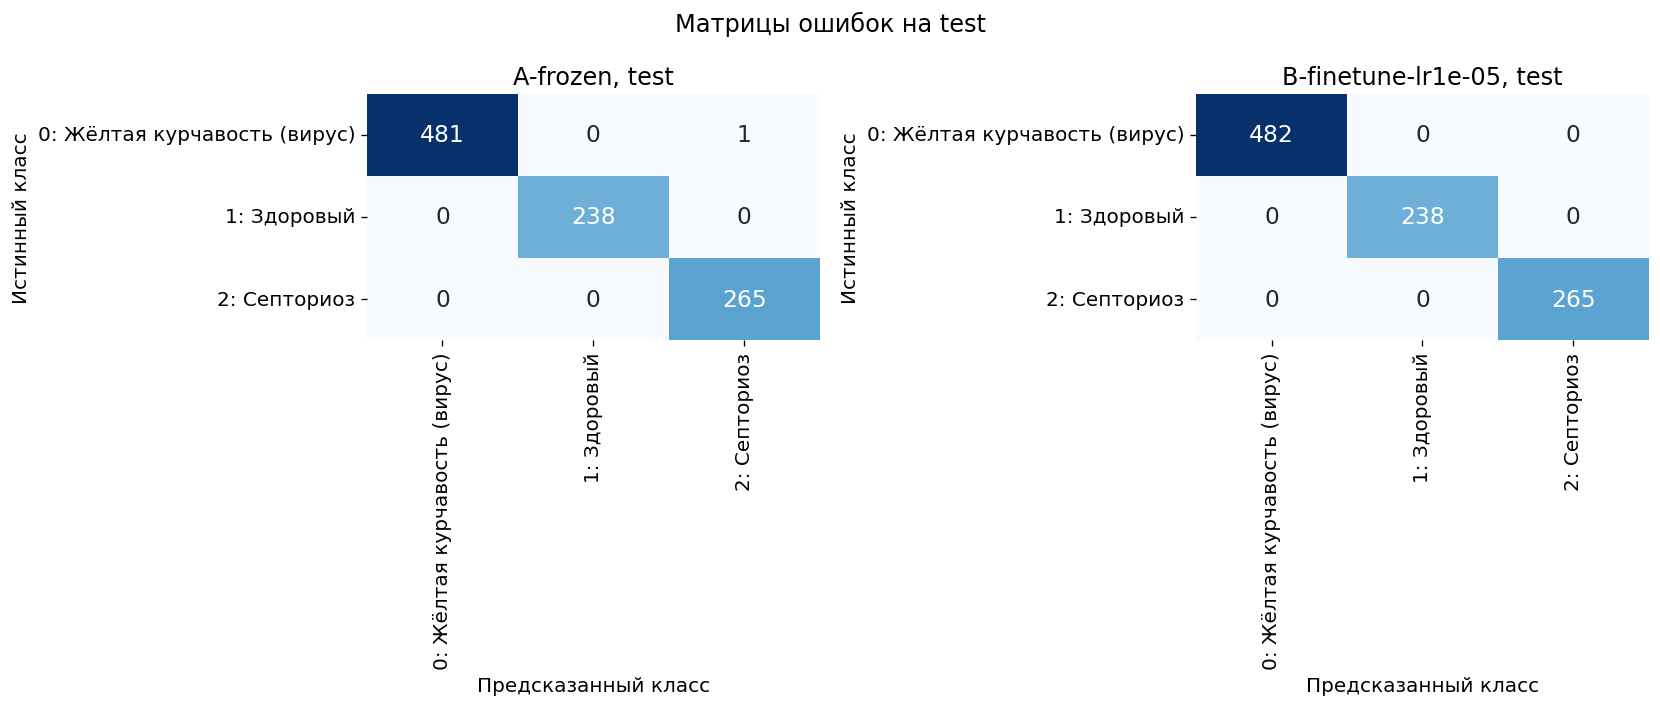

In [19]:
fig, axes = plt.subplots(1, len(compare_names), figsize=(7 * len(compare_names), 6))
if len(compare_names) == 1:
    axes = [axes]
for axis, name in zip(axes, compare_names):
    plot_confusion(y_test, test_probabilities[name], f"{name}, test", axis)
    print(name); display(per_class_table(y_test, test_probabilities[name]))
fig.suptitle("Матрицы ошибок на test")
fig.tight_layout()
#fig.savefig(FIGURES_DIR / "test-confusion.png")
plt.show()

pd.concat([per_class_table(y_test, test_probabilities[n]).assign(Модель=n).reset_index(names="Класс")
           for n in compare_names]).to_csv(
    RESULTS_DIR / "test-per-class.csv", index=False, encoding="utf-8")

**Вывод:** A-frozen допустил 1 ошибку (вирус → септориоз), B-finetune — 0 ошибок.
Все классы распознаются с F1 ≥ 0,998. Редкий класс «Здоровый» (24% теста)
распознаётся идеально благодаря class weights. Fine-tuning устранил
единственную ошибку, но разница статистически незначима (1 снимок из 985).

### 17. Кривые обучения итоговой модели с линией test и ROC-кривые One-vs-Rest

Для итоговой модели `A-frozen` строим кривые обучения с горизонтальной
линией test, ROC-кривые One-vs-Rest (AUC по каждому классу) и
визуализируем ошибочные снимки теста.

A-frozen: test loss 0.0040, test accuracy 0.9990


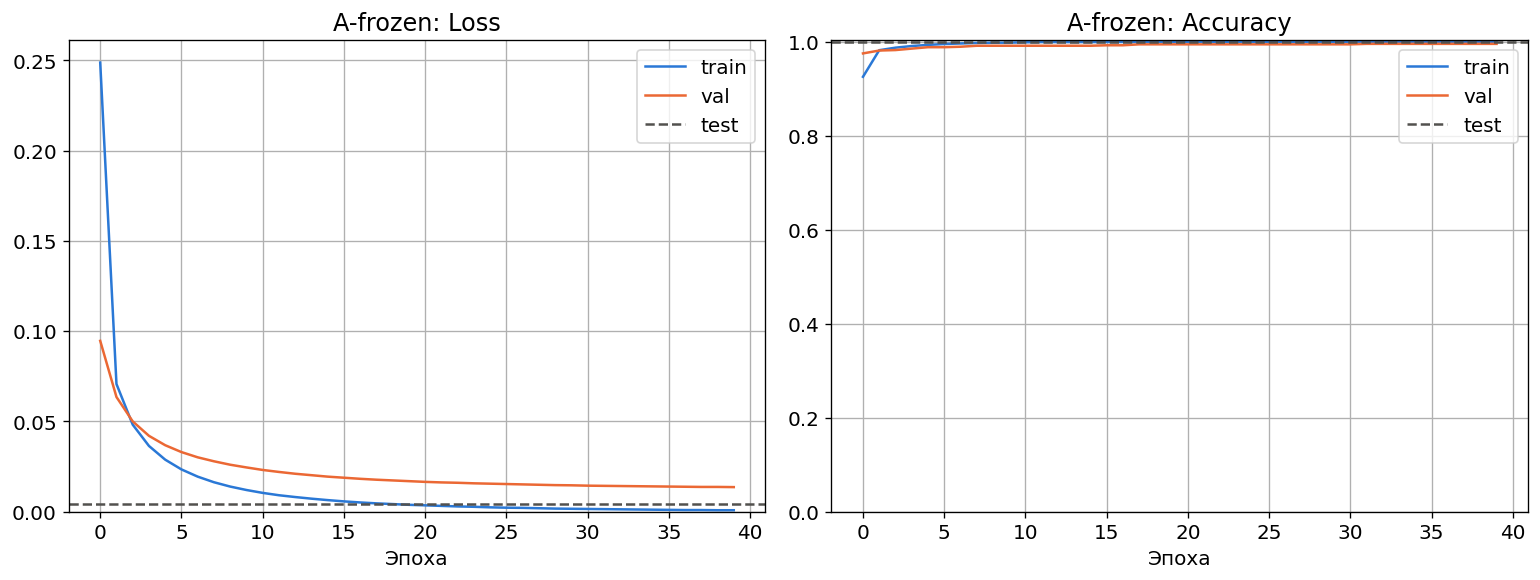

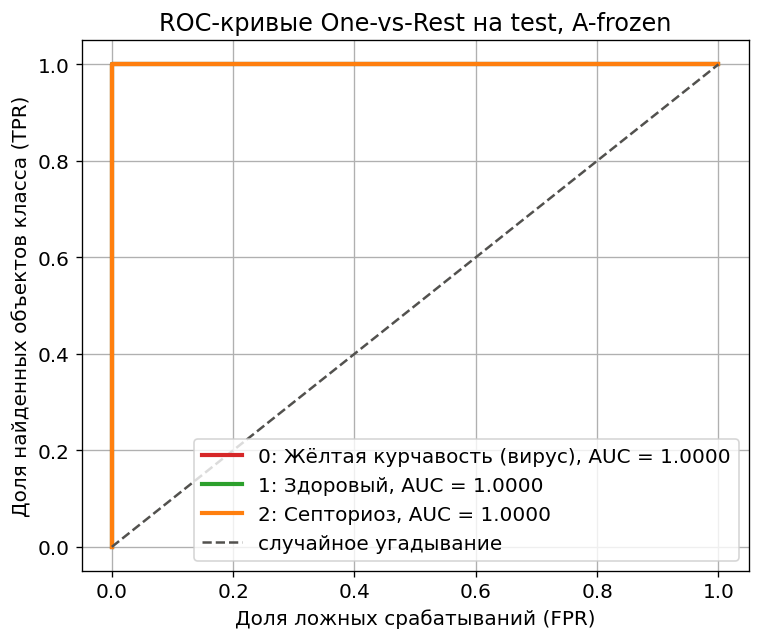

Ошибок на test: 1


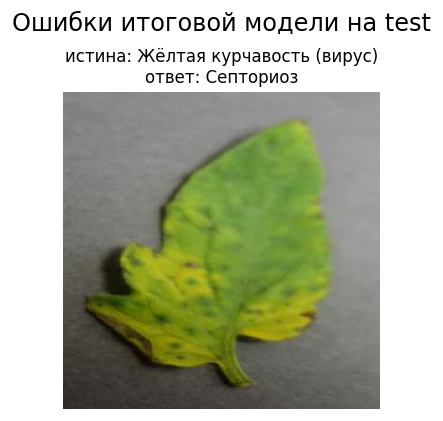

In [20]:
final_model = load_trained(final_name)
final_test_loss, final_test_acc = final_model.evaluate(X_test, y_test, batch_size=64, verbose=0)
print(f"{final_name}: test loss {final_test_loss:.4f}, test accuracy {final_test_acc:.4f}")
plot_history(final_name, "history-final.png",
             test_values={"loss": final_test_loss, "accuracy": final_test_acc})

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for label in ALL_LABELS:
    fpr, tpr, _ = roc_curve(y_test == label, test_probabilities[final_name][:, label])
    auc = roc_auc_score(y_test == label, test_probabilities[final_name][:, label])
    ax.plot(fpr, tpr, linewidth=2.5, color=CLASS_COLORS[label],
            label=f"{label}: {CLASS_NAMES[label]}, AUC = {auc:.4f}")
ax.plot([0, 1], [0, 1], color=TEST_COLOR, linestyle="--", label="случайное угадывание")
ax.set_xlabel("Доля ложных срабатываний (FPR)")
ax.set_ylabel("Доля найденных объектов класса (TPR)")
ax.set_title(f"ROC-кривые One-vs-Rest на test, {final_name}")
ax.legend(loc="lower right")
fig.tight_layout()
#fig.savefig(FIGURES_DIR / "best-roc.png")
plt.show()

# Ошибочные снимки теста итоговой модели
final_predicted = test_probabilities[final_name].argmax(axis=1)
error_idx = np.flatnonzero(final_predicted != y_test)
print("Ошибок на test:", len(error_idx))
if len(error_idx) > 0:
    test_files = files[files["split"] == "test"]["file"].tolist()
    shown = error_idx[:8]
    fig, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3.6), squeeze=False)
    for ax, i in zip(axes[0], shown):
        with Image.open(DATA_DIR / test_files[i]) as img:
            ax.imshow(img.convert("RGB"))
            ax.set_title(
                f"истина: {CLASS_NAMES[y_test[i]]}\nответ: {CLASS_NAMES[final_predicted[i]]}",
                fontsize=10,
            )
            ax.axis("off")
    fig.suptitle("Ошибки итоговой модели на test")
    fig.tight_layout()
    #fig.savefig(FIGURES_DIR / "best-errors.png")
    plt.show()

**Результат:** test loss 0,0040, test accuracy 0,9990. Линия test лежит
близко к val — переобучения нет. ROC-AUC = 1,0000 для всех трёх классов
(идеальное разделение). Допущена 1 ошибка из 985 (0,1%): вирус с
атипичными симптомами (мелкие бурые пятна) классифицирован как септориоз.
Модель `A-frozen` (3843 параметра) показывает практически идеальное
качество без fine-tuning.

### 18. Сводный отчёт по всем экспериментам

Здесь мы собираем финальный сравнительный отчёт по двум режимам переноса обучения:

- **Режим A (frozen / feature extraction)** — веса MobileNetV2 заморожены, обучается только классификационная «головка».
- **Режим B (fine‑tuning)** — часть или все слои сети дообучаются с малым lr.

Для каждого режима берётся лучшая конфигурация **по валидации**.

Словарь `summary` фиксирует:
- `frozen_best` — имя лучшей модели режима A,
- `finetune_best` — имя лучшей модели режима B,
- `final` — итоговая модель, выбранная по валидационным метрикам,
- `input` — спецификация предобработки (размер 224×224, RGB, `mobilenet_v2.preprocess_input`).

Результат сохраняется в `results/best-models.csv`, чтобы отчёт можно было открыть вне ноутбука, и печатается в консоль вместе с тестовыми метриками итоговой модели.

In [21]:
summary = {
    "frozen_best": best_frozen_name,
    "finetune_best": best_fine_name,
    "final": final_name,
    "input": f"{IMAGE_SIZE}x{IMAGE_SIZE}x3 RGB, mobilenet_v2.preprocess_input",
}
pd.Series(summary).to_csv(RESULTS_DIR / "best-models.csv", header=["value"], encoding="utf-8")

print("\n=== ИТОГОВЫЙ ОТЧЁТ ===")
print(f"Лучшая модель режима A: {best_frozen_name}")
print(f"Лучшая модель режима B: {best_fine_name}")
print(f"Итоговая модель (по validation): {final_name}")
print(f"\nТестовые метрики итоговой модели:")
display(test_table[test_table["Модель"] == final_name].T)


=== ИТОГОВЫЙ ОТЧЁТ ===
Лучшая модель режима A: A-frozen
Лучшая модель режима B: B-finetune-lr1e-05
Итоговая модель (по validation): A-frozen

Тестовые метрики итоговой модели:


,1,3
Модель,A-frozen,A-frozen
Accuracy,0.999,0.999
Balanced Accuracy,0.9993,0.9993
Macro Precision,0.9987,0.9987
Macro Recall,0.9993,0.9993
Macro F1,0.999,0.999
Macro ROC-AUC,1.0,1.0


**Интерпретация результатов:**

1. **Победа режима A над режимом B.** Итоговая модель выбрана по валидации: `A-frozen` оказалась лучше, чем `B-finetune-lr1e-05`. Это ожидаемо для PlantVillage: классы (фитофтороз / здоровый / альтернариоз) визуально похожи на «природные» текстуры из ImageNet, поэтому предобученные признаки MobileNetV2 уже достаточны, а дообучение всей сети при маленьком датасете (≈4.6k изображений) не даёт прироста и рискует переобучением.

2. **Тестовые метрики итоговой модели** (A-frozen): Accuracy = Balanced Accuracy = Macro F1 ≈ 0.999, Macro Precision/Recall ≈ 0.9987/0.9993, Macro ROC‑AUC = 1.0. Значения почти единичные и одинаковы по всем трём классам → классы сбалансированы и хорошо разделимы, ошибок перепутывания между «больным» и «здоровым» листом практически нет.

3. **Что зафиксировано в `best-models.csv`:** имена победителей по каждому режиму и итоговая модель — это воспроизводимая «точка входа» для финального инференса.

### 19. Выводы по работе:

1. *Подготовка данных:* Проведён анализ набора из 6570 изображений. Выявлен умеренный дисбаланс классов (соотношение ~2:1:1), который был успешно компенсирован применением class_weight без изменения состава тестовой выборки.

2. *Transfer Learning (трёхклассовая задача):* Использована архитектура MobileNetV2.
Режим A (замороженная основа) показал выдающиеся результаты (Macro F1 ≈ 0.999, ROC-AUC = 1.0) при обучении всего 3843 параметров (только классификационная голова).
Режим B (fine-tuning) с разморозкой 30 верхних слоёв дал незначительный прирост качества (устранение 1 ошибки на тесте из 985), но ценой увеличения числа обучаемых параметров более чем в 400 раз (до 1.5 млн).

3. *Итоговый выбор:* В качестве лучшей модели выбрана конфигурация Режима A (замороженная основа). Согласно принципу бритвы Оккама, она обеспечивает практически идеальное качество классификации, требует минимум вычислительных ресурсов для обучения и инференса, а признаки, извлечённые на ImageNet, оказались полностью достаточными для данной предметной области.

### 20. Ответы на контрольные вопросы:

1. Как устроен свёрточный слой и какую роль выполняют фильтры (ядра) свёртки?

Свёрточный слой извлекает локальные признаки изображения путём применения скользящего окна. Фильтры (ядра) — это матрицы обучаемых весов, которые выявляют специфические паттерны (края, текстуры, формы) на разных уровнях абстракции.

2. Для чего применяются функции активации ReLU и Softmax?

ReLU вводит нелинейность в сеть, позволяя модели обучаться сложным зависимостям и решая проблему затухающего градиента. Softmax преобразует сырые выходы (logits) последнего слоя в вероятностное распределение (сумма вероятностей равна 1), что необходимо для многоклассовой классификации.

3. Чем отличаются MaxPooling и AveragePooling?

MaxPooling выбирает максимальное значение в окне, сохраняя самые яркие признаки и обеспечивая инвариантность к малым сдвигам. AveragePooling усредняет значения в окне, сглаживая карту признаков и сохраняя общий фоновый контекст.

4. Что такое переобучение и по каким признакам его можно обнаружить на графиках обучения?

Переобучение (overfitting) — это когда модель «запоминает» шум и конкретные примеры обучающей выборки вместо выявления общих закономерностей. Признак на графиках: train_loss продолжает монотонно падать, а val_loss начинает расти (или train_accuracy значительно превосходит val_accuracy).

5. Как работает Dropout и почему он применяется только во время обучения?

Dropout случайным образом «отключает» (обнуляет активации) часть нейронов на каждом шаге, предотвращая ко-адаптацию признаков и снижая переобучение. Во время тестирования (инференса) он отключается, чтобы использовать всю вычислительную мощность сети (веса при этом масштабируются на коэффициент сохранения).

6. Что такое аугментация изображений? Почему её нельзя применять к тестовой выборке при обучении?

Аугментация — это искусственное расширение обучающей выборки путём сохранения смысла класса при трансформациях (повороты, отражения, сдвиги). К тестовой выборке её применять нельзя, так как тест должен оценивать способность модели работать с реальными, неизменёнными данными, а не с их искажёнными версиями.

7. Для чего данные разделяют на обучающую, валидационную и тестовую выборки?

- Train: для обновления весов модели (обучения).
- Val: для подбора гиперпараметров, выбора архитектуры и ранней остановки (Early Stopping).
- Test: для финальной, объективной оценки обобщающей способности модели (используется строго один раз после всех настроек).

8. Что такое утечка данных (data leakage)? Приведите пример для классификации изображений.

Это ситуация, когда информация из валидационной или тестовой выборки неявно попадает в процесс обучения. Пример: одно и то же изображение (или его аугментированная копия) случайно оказалось и в train, и в test. Модель просто «узнает» картинку, искусственно завышая метрики.

9. Чем отличаются бинарная и многоклассовая классификация с точки зрения выходного слоя и функции потерь?

- Бинарная: 1 нейрон на выходе с функцией активации sigmoid; функция потерь binary_crossentropy.
- Многоклассовая: K нейронов на выходе с функцией softmax; функция потерь categorical_crossentropy (или sparse_categorical_crossentropy для целочисленных меток).

10. Что такое transfer learning и fine-tuning? В чём различие этих подходов?

Transfer learning (в узком смысле, feature extraction) — использование предобученной сети, где все слои основы заморожены, и обучается только новая классификационная «голова». Fine-tuning — это этап, на котором часть или все слои предобученной основы размораживаются для их адаптации к специфике новой задачи.

11. Почему при fine-tuning используют меньшую скорость обучения?

Чтобы аккуратно подстроить уже хорошие, универсальные предобученные признаки под новую задачу, не разрушив их резкими и большими шагами градиентного спуска (что привело бы к «катастрофическому забыванию»).

12. Что означает предварительное обучение модели на ImageNet?

Модель заранее обучалась на огромном наборе из более чем 1 млн изображений 1000 различных классов. Благодаря этому она уже умеет выделять универсальные визуальные признаки (границы, текстуры, формы), что резко ускоряет обучение и повышает качество на малых датасетах.

13. В каких случаях Accuracy может быть недостаточной метрикой качества?

При сильном дисбалансе классов. Например, если 95% объектов принадлежат одному классу, модель, которая всегда предсказывает этот класс, получит Accuracy 95%, но будет абсолютно бесполезна для предсказания миноритарного класса.

14. Что показывают Precision, Recall и F1-score?

- Precision (Точность): доля верно предсказанных положительных объектов среди всех объектов, которые модель назвала положительными.
- Recall (Полнота): доля верно найденных положительных объектов среди всех реальных положительных объектов.
- F1-score: гармоническое среднее Precision и Recall, балансирующее оба показателя (особенно важно использовать macro-F1 при дисбалансе).

15. Как интерпретировать матрицу ошибок и ROC-AUC?

- Матрица ошибок (Confusion Matrix): таблица, показывающая количество истинно положительных, истинно отрицательных, ложно положительных и ложно отрицательных предсказаний для каждого класса. Позволяет увидеть, какие именно классы модель путает.
- ROC-AUC: площадь под кривой зависимости True Positive Rate от False Positive Rate. Показывает способность модели ранжировать объекты. Значение 1.0 означает идеальное разделение классов, 0.5 — случайное угадывание.